# 使用说明
从上到下逐格运行。每格下方已有本次实际执行输出，不需要先运行也能读。
改参数后请重新运行后续格。图中数字幅度没有校准成声压，不代表耳机声压大小。
仅使用 NumPy、SciPy、Matplotlib；不录音、不自动播放、不下载模型。
图形显示由本机已安装的中文字体决定；本次生成使用微软雅黑。


# 练习本四：两个算法如何从几行代码起步

先做AEC参数更新，再做极小CTC概率。两者任务不同，共同点是“手算能解释，代码可核对”。


真实系数/学习系数： 0.6 0.5999999999999995


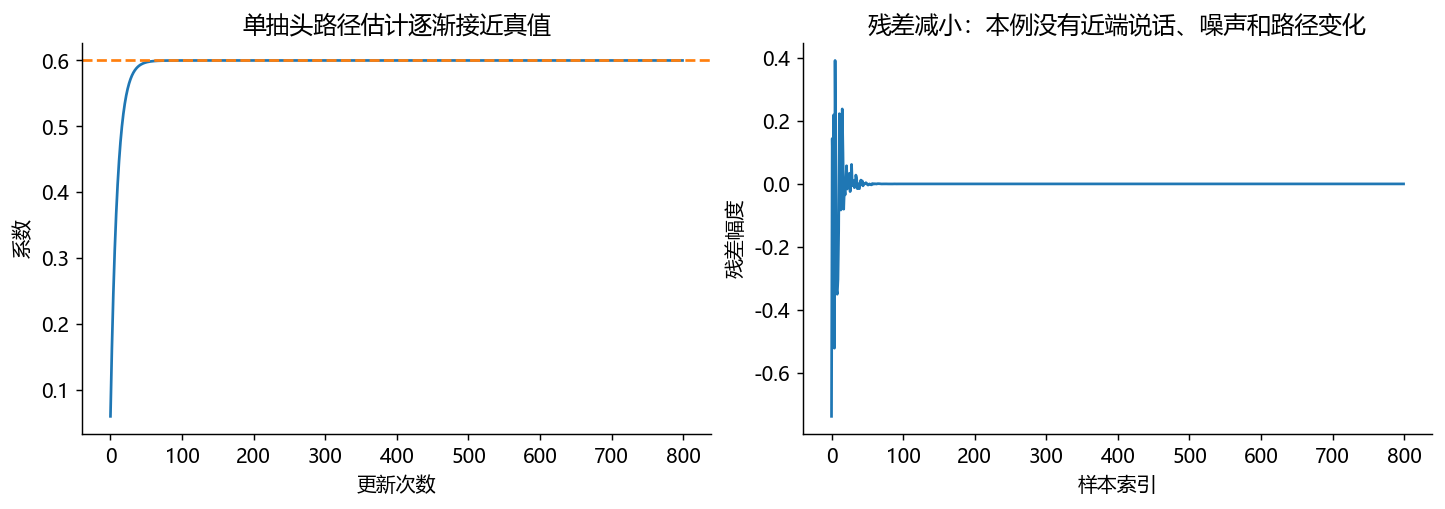

In [1]:
import numpy as np
import matplotlib.pyplot as plt
rng = np.random.default_rng(41)
reference = rng.normal(size=800)        # 设备已知的远端参考
true_gain = 0.6
microphone = true_gain*reference        # 极简回声路径：只有一个系数
weight = 0.0                           # 初始不知道路径
history, residual = [], []
for x, d in zip(reference, microphone):
    echo_estimate = weight*x            # 用当前系数预测回声
    error = d-echo_estimate             # 麦克风减预测，保留残差
    weight += 0.1*error*x/(x*x+1e-8)    # NLMS归一化更新，分母小量防除零
    history.append(weight)
    residual.append(error)
print('真实系数/学习系数：', true_gain, weight)
assert abs(weight-true_gain) < 1e-6
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), layout='constrained')
axes[0].plot(history); axes[0].axhline(true_gain, color='C1', linestyle='--')
axes[0].set(xlabel='更新次数', ylabel='系数', title='单抽头路径估计逐渐接近真值')
axes[1].plot(residual)
axes[1].set(xlabel='样本索引', ylabel='残差幅度', title='残差减小：本例没有近端说话、噪声和路径变化')


不要把这张漂亮的收敛图当真实通话效果。真实AEC还要面对几十到几千抽头、参考延迟、双讲、扬声器非线性与时钟漂移。第08章会逐层添加问题。下面换到CTC：只有空白和“啊”两个类别，两步输出。


三条合法路径概率： [np.float64(0.27999999999999997), np.float64(0.18), np.float64(0.42)] 总概率： 0.8799999999999999 负对数似然： 0.12783337150988502


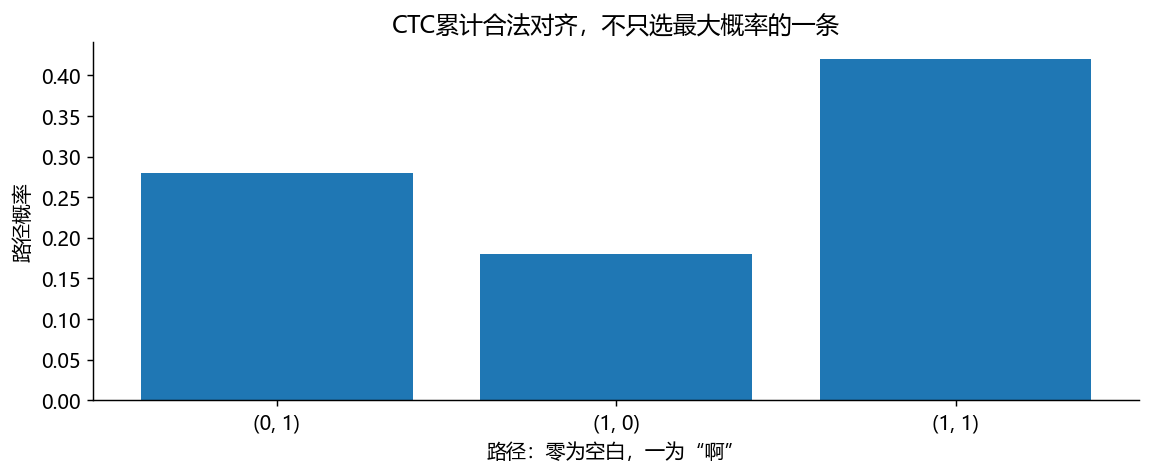

In [2]:
import itertools
probs = np.array([[0.4, 0.6], [0.3, 0.7]])  # 两行是时间，两列为空白/啊
def collapse(path):
    output, previous = [], None
    for token in path:
        if token != previous and token != 0:  # 合并相邻重复，同时不输出空白
            output.append(token)
        previous = token                     # 空白也必须更新previous
    return output
total = 0.0
labels, values = [], []
for path in itertools.product([0, 1], repeat=2):
    probability = probs[0, path[0]]*probs[1, path[1]]
    if collapse(path) == [1]:                 # 只累计能折叠成一个“啊”的路径
        total += probability
        labels.append(str(path)); values.append(probability)
print('三条合法路径概率：', values, '总概率：', total, '负对数似然：', -np.log(total))
assert abs(total-0.88) < 1e-12
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.bar(labels, values)
ax.set(xlabel='路径：零为空白，一为“啊”', ylabel='路径概率', title='CTC累计合法对齐，不只选最大概率的一条')
fig.tight_layout()


答案核对：空白→啊为0.28；啊→空白为0.18；啊→啊为0.42，合计0.88。若目标是“啊啊”，只有两步还不够，需要空白隔开重复字符。完整ASR会把很多帧、很多类别的求和交给动态规划；本练习不是一个识别模型。
